# Checking and cleaning network topology

In the previous section, we checked whether it is possible to travel between all parts of a network. In this section, we look at the structure of a network in more detail and see how network data can be cleaned before the analysis. We start by counting how many edges are connected to each node of a street network, and use this information to simplify the network. Then, we check whether the streets in a street dataset are correctly connected to each other, and fix the errors that we find.

First, let's retrieve the same drivable street network of the Helsinki city centre as in the previous section, and keep only its largest strongly connected component (see Chapter 8.3):

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import neatnet
import networkx as nx
import osmnx as ox
import pandas as pd

center_point = (60.162, 24.937)
G = ox.graph_from_point(center_point, dist=3500, network_type="drive", simplify=False)
G = ox.truncate.largest_component(G, strongly=True)

## Node degree

The **degree** of a node is the number of edges that are connected to it. In a street network, the degree tells how many street segments (i.e. parts of streets between two nodes) meet at a node. For instance, a node with degree 1 is a dead end, a node with degree 3 is an intersection where three street segments meet (such as a T-junction), and a node with degree 4 is an intersection of four street segments (such as a crossroads).

When calculating the degree, we need to be careful with directed graphs. As we learned in Chapter 8.1, a street that can be traveled in both directions is represented in a directed graph with two edges, one for each direction (called reciprocal edges). Hence, if we calculated the degree directly from our directed graph, each two-way street would be counted twice. To count each street segment only once, we first convert our graph into an undirected graph with the `ox.convert.to_undirected()` function:

In [2]:
G_undirected = ox.convert.to_undirected(G)

Now we can get the degree of every node with the `.degree()` method of the graph, which returns pairs of node ids and degrees. Let's extract the nodes and edges from the graph as GeoDataFrames and add the degrees as a new column to the `nodes` GeoDataFrame. As with the travel times in Chapter 8.2, we convert the degrees into a dictionary and further into a `pandas` `Series` that uses the node ids as its index, so that the degrees are matched with the correct nodes. Finally, we count how many nodes have each degree value:

In [3]:
nodes, edges = ox.graph_to_gdfs(G)
nodes["degree"] = pd.Series(dict(G_undirected.degree()))
nodes["degree"].value_counts().sort_index()

degree
1      220
2    15617
3      988
4      506
5       16
6        1
Name: count, dtype: int64

As we can see, a large share of the nodes have a degree of 2. These nodes are not intersections at all, but points in the middle of a street where the street simply continues from one edge to the next. They are part of our network because we retrieved the data with `simplify=False`, which keeps all the points that were used to draw the streets in OpenStreetMap.

The nodes with degree 1 are either dead ends or places where a street was cut at the border of the area, and the nodes with degree 3 or more are intersections. Let's see where these nodes are located by plotting them on a map, colored by their degree:

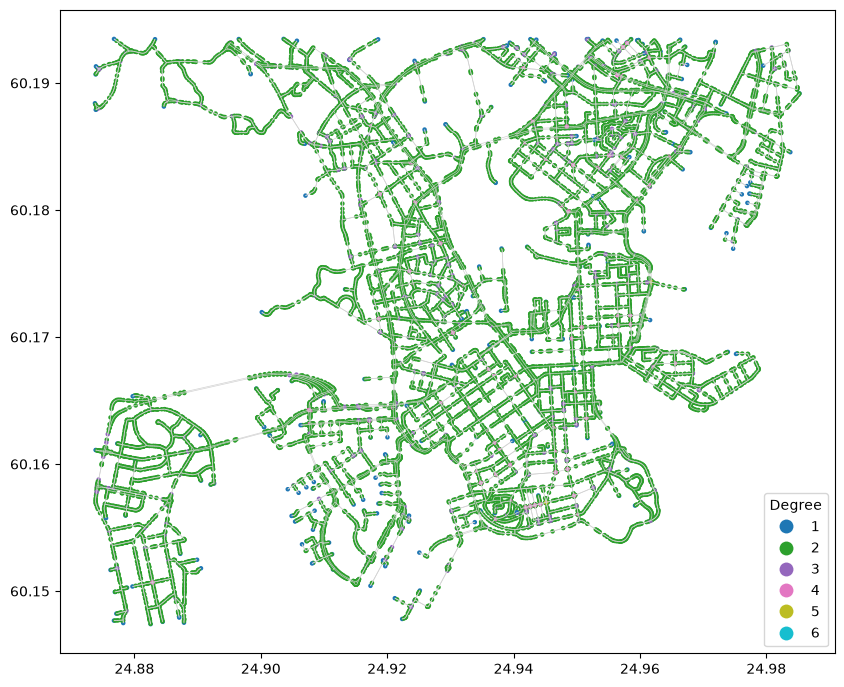

In [4]:
ax = edges.plot(color="lightgrey", linewidth=0.5, figsize=(10, 10))
ax = nodes.plot(
    ax=ax,
    column="degree",
    categorical=True,
    cmap="tab10",
    markersize=5,
    legend=True,
    legend_kwds={"title": "Degree"},
)

_**Figure 8.X.** Nodes of the street network colored by their degree._

As we can see, the nodes with degree 2 are spread along the streets all over the network. Because these nodes are not real intersections, they do not tell much about the structure of the street network, but they make the network larger than necessary. Next, we will see how we can clean the network from such nodes.

## Simplifying the network

We can clean the network by merging all the street elements that are between two intersections into one. This process is called **simplification**, and it is the same step that `pyrosm` did for us automatically in Chapter 8.2.

With `osmnx`, we can simplify a graph with the `ox.simplify_graph()` function, which removes the nodes in the middle of the streets and merges the edges connected to them into a single edge. The shape of the streets is not lost, because `osmnx` stores the shape of the merged edges as a `LineString` in the `geometry` attribute of the new edge. Let's simplify our graph and compare the number of nodes and edges before and after the simplification:

In [5]:
G_simplified = ox.simplify_graph(G)

print("Nodes before simplification:", G.number_of_nodes())
print("Nodes after simplification:", G_simplified.number_of_nodes())
print("Edges before simplification:", G.number_of_edges())
print("Edges after simplification:", G_simplified.number_of_edges())

Nodes before simplification: 17348
Nodes after simplification: 1773
Edges before simplification: 27866
Edges after simplification: 3985


As we can see, the simplification removed most of the nodes and edges from the network. This is in line with what we found when we calculated the degrees: most of the nodes had a degree of 2, i.e. they were not real intersections. Let's visualize the difference by plotting the nodes of the network before and after the simplification next to each other:

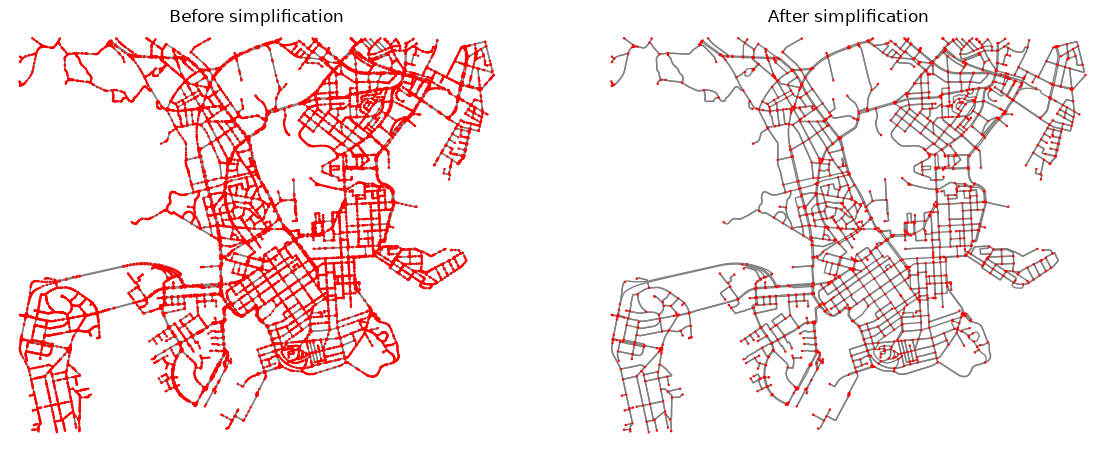

In [6]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 7))

ox.plot_graph(
    G,
    ax=ax1,
    node_size=3,
    node_color="red",
    edge_color="grey",
    bgcolor="white",
    show=False,
)
ax1.set_title("Before simplification")

ox.plot_graph(
    G_simplified,
    ax=ax2,
    node_size=3,
    node_color="red",
    edge_color="grey",
    bgcolor="white",
    show=False,
)
ax2.set_title("After simplification");

_**Figure 8.X.** Nodes of the street network before (left) and after (right) the simplification._

As we can see, after the simplification the nodes are mainly located at the intersections and at the ends of the streets. Now the nodes of our network describe the actual structure of the street network, and the network is also smaller, which makes the analyses faster.

Another common issue in street networks is that a single intersection is represented with several nodes, which typically happens when the two driving directions of a large street are drawn as separate lines in the data. For fixing this issue, `osmnx` has the `ox.consolidate_intersections()` function that merges nodes that are close to each other into a single node, but we do not use it in this section.

## Finding topology errors

As we learned in Chapter 8.1, the way in which the nodes and edges of a network are connected to each other is called network topology. When we create a network from lines, such as the street segments of the Digiroad data in Chapter 8.1, two segments are connected only if they end at exactly the same point. Real-world data often contain errors that break this rule.

For instance, a street may end a few meters before the street that it should join (a gap), it may continue a few meters past it (an overshoot), it may end on the middle of another street without a node that would connect them (a missing node), or the same street may be in the data twice (a duplicate). Such errors are difficult to notice on a map, but they can make a route impossible or force it to take a long detour.

Let's take a look at a part of the Digiroad street data from Chapter 8.1 that covers the Kamppi, Punavuori, Ruoholahti and Jätkäsaari districts of Helsinki. To demonstrate the checks, we have added some typical errors to this data. Let's read the data with `geopandas` and plot it:

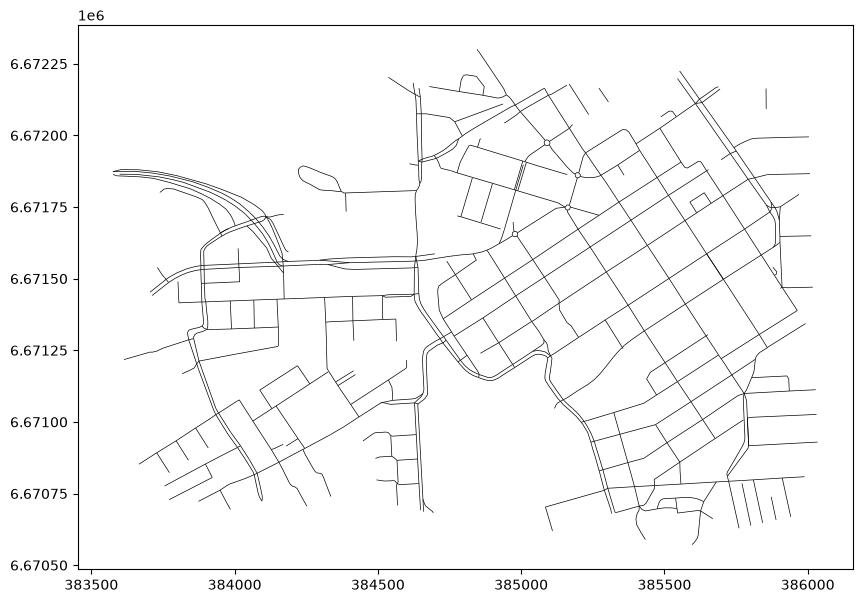

In [7]:
streets = gpd.read_file("data/digiroad_topology_errors.gpkg")
ax = streets.plot(color="black", linewidth=0.5, figsize=(10, 8))

_**Figure 8.X.** Street data for the Kamppi, Punavuori, Ruoholahti and Jätkäsaari districts of Helsinki, with some added topology errors._

As we can see, the errors are not visible on the map. To check the topology, we first convert the lines into a graph with the `gdf_to_graph()` function that we wrote in Chapter 8.1. The function uses the end points of the lines as nodes and the lines as edges, and it creates an undirected `MultiGraph`, which keeps also the duplicate lines as separate edges. Let's define the function again:

In [8]:
def gdf_to_graph(gdf):
    """Creates a NetworkX MultiGraph from GeoDataFrame consisting of LineString objects.

    Parameters
    ----------

    gdf : GeoDataFrame
        GeoDataFrame containing the LineString data.

    """

    # Create the NetworkX graph
    graph = nx.MultiGraph()

    # Generate edge dictionary
    for row in gdf.itertuples():
        coords = row.geometry.coords

        # Get first and last node of the edge (excluding vertices)
        first, last = coords[0], coords[-1]

        # Edge attributes
        edge_attr = row._asdict()

        graph.add_edge(first, last, **edge_attr)

    # Generate node attributes
    node_attrs = {
        node: {"coords": (node[0], node[1]), "x": node[0], "y": node[1]}
        for node in graph.nodes
    }
    nx.set_node_attributes(graph, node_attrs)

    # Relabel the indices
    graph = nx.convert_node_labels_to_integers(graph)

    # Add some useful attributes
    graph.graph["crs"] = gdf.crs

    return graph

Now we can create the graph and check whether it is possible to travel between all parts of the network by counting its connected components with the `nx.number_connected_components()` function that we used in Chapter 8.3:

In [9]:
G_streets = gdf_to_graph(streets)
nx.number_connected_components(G_streets)

8

As we can see, the network consists of 8 separate parts. Some of them can be real, for instance short pieces of streets that were cut at the border of the area, but some of them can be caused by errors. To find the places where the errors may be located, let's look at the dead ends of the network, i.e. the nodes whose degree is 1.

We can get the nodes of the graph as a GeoDataFrame with the `ox.graph_to_gdfs()` function in the same way as above, because our function stored the coordinates of the nodes as `x` and `y` attributes and the coordinate reference system as the `crs` attribute of the graph. Because the graph is already undirected, we can add the degrees with its `.degree()` method directly and select the nodes whose degree is 1:

In [10]:
nodes = ox.graph_to_gdfs(G_streets, edges=False)
nodes["degree"] = pd.Series(dict(G_streets.degree()))
dead_ends = nodes.loc[nodes["degree"] == 1]
len(dead_ends)

103

Most of these dead ends are real, i.e. streets that end in a cul-de-sac or are cut at the border of the area. However, a dead end that is located very close to another street is suspicious, because it may be a gap or a missing node.

Let's find the dead ends that have another street within 5 meters. We enlarge each dead end into a circle with a radius of 5 meters with the `.buffer()` method and count the street segments that intersect each circle with a spatial join (see Chapter 6.7). Because each dead end touches its own segment, the ones with more than one intersecting segment are close to another street. Finally, we plot all dead ends in black and the suspicious ones in red:

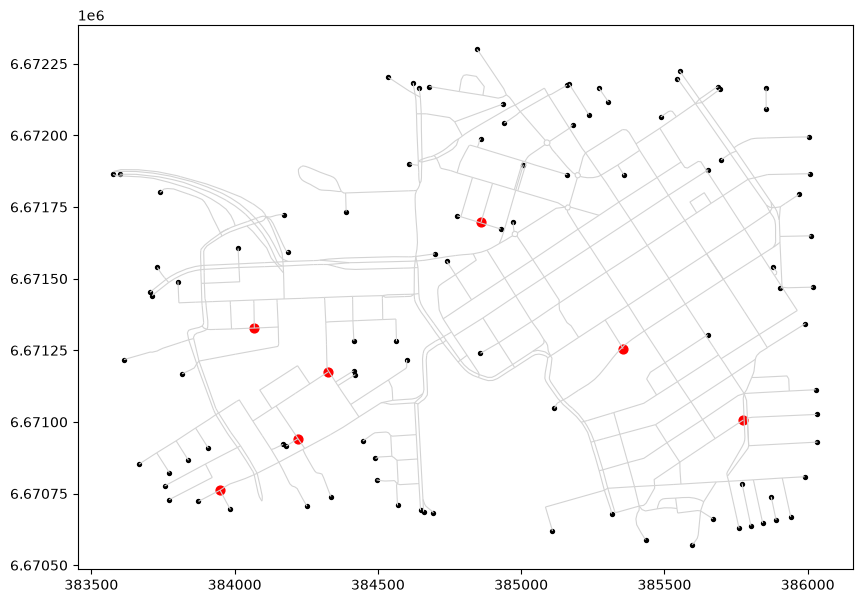

In [11]:
dead_end_areas = dead_ends.set_geometry(dead_ends.buffer(5))
nearby = gpd.sjoin(dead_end_areas, streets, predicate="intersects")
segment_counts = nearby.groupby(level=0).size()
suspicious = dead_ends.loc[segment_counts[segment_counts > 1].index]

ax = streets.plot(color="lightgrey", linewidth=0.8, figsize=(10, 8))
ax = dead_ends.plot(ax=ax, color="black", markersize=8)
ax = suspicious.plot(ax=ax, color="red", markersize=40)

_**Figure 8.X.** Dead ends of the street network (in black) and the dead ends that are located within 5 meters from another street (in red)._

Figure 8.X shows 7 suspicious dead ends. Six of them are the errors that we added to the data. The seventh one is an error that was already in our data: Sinebrychoffinkatu crosses Mallaskatu and ends a few meters past it (an overshoot), without a node at the crossing point.

Next, let's check whether the data contain duplicate lines. We can find them with the `.duplicated()` method, which marks every row that is identical to some earlier row. Before the comparison, we convert the geometries into a standard form with the `.normalize()` method, so that the same line is detected as a duplicate even if its coordinates are stored in the opposite order:

In [12]:
duplicates = streets.geometry.normalize().duplicated()
streets.loc[duplicates]

,id,name,geometry
730,1733,Annankatu,"LINESTRING (385705.817 6671497.843, 385647.194..."
731,1317,Laivurinkatu,"LINESTRING (385794.028 6670916.935, 385789.424..."
732,1687,Salmisaarenkatu,"LINESTRING (383950.563 6671659.127, 383955.416..."


As we can see, three street segments are in the data twice. Finally, let's check whether there are lines that cross each other without a node at the crossing point. We can find them with a spatial join that uses the `"crosses"` predicate. Each pair of crossing lines is found twice (the first line crosses the second one and vice versa), so we divide the number of rows by two:

In [13]:
crossings = gpd.sjoin(streets, streets, predicate="crosses")
len(crossings) // 2

12

As we can see, there are 12 pairs of lines that cross each other without a node. However, not all of them are errors: streets that cross each other on different levels, such as a street on a bridge and a street below it, should not be connected. Telling them apart would need additional information, such as aerial images or attributes that tell whether a street is on a bridge or in a tunnel, and hence we do not fix the crossings automatically.

## Fixing topology errors

Now that we have found the errors, let's fix them with the `neatnet`[^neatnet] library, which provides tools for cleaning street networks. The `neatnet.extend_lines()` function extends the loose ends of lines by at most the given distance (`tolerance`, here 5 meters) until they touch another line, which closes the gaps. The `neatnet.fix_topology()` function then adds a node wherever the end of a line touches another line (which fixes the missing nodes), removes duplicate lines, and simplifies the network in the same way as we did earlier in this section:

In [14]:
streets_extended = neatnet.extend_lines(streets, tolerance=5)
streets_fixed = neatnet.fix_topology(streets_extended)

Let's check the result in the same way as above by counting the connected components, dead ends and duplicates of the fixed data:

In [15]:
G_fixed = gdf_to_graph(streets_fixed)
nodes_fixed = ox.graph_to_gdfs(G_fixed, edges=False)
nodes_fixed["degree"] = pd.Series(dict(G_fixed.degree()))

print("Connected components:", nx.number_connected_components(G_fixed))
print("Dead ends:", (nodes_fixed["degree"] == 1).sum())
print("Duplicates:", streets_fixed.geometry.normalize().duplicated().sum())

Connected components: 6
Dead ends: 97
Duplicates: 0


As we can see, the number of connected components decreased from 8 to 6, the number of dead ends decreased by six, and there are no duplicates left. The remaining six connected components were already in the original data. Let's zoom in to one of the suspicious dead ends and compare the data before and after the fix:

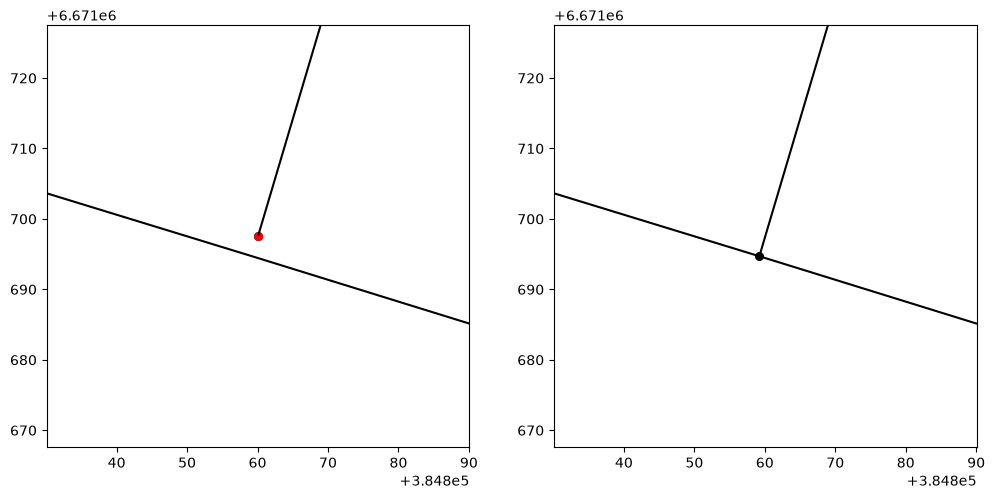

In [16]:
location = suspicious.geometry.iloc[0]
xmin, ymin, xmax, ymax = location.buffer(30).bounds

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 6))
for ax, lines, points in [(ax1, streets, nodes), (ax2, streets_fixed, nodes_fixed)]:
    lines.plot(ax=ax, color="black")
    points.plot(ax=ax, color="black", markersize=30)
    points.loc[points["degree"] == 1].plot(ax=ax, color="red", markersize=30)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

_**Figure 8.X.** A gap between two streets before (left) and after (right) fixing the topology. The nodes are shown in black and the dead ends in red._

On the left, the side street ends before it reaches the street that it should join, and its end is a dead end. On the right, the side street has been extended to the other street, and there is a node where the two streets meet.

Notice, however, that the overshoot at Sinebrychoffinkatu is still in the data, because the functions that we used do not shorten lines that continue past another line. In addition, `fix_topology()` merged the street segments that met at nodes of degree 2, which is why the fixed data contain fewer segments than the original data. If the data had attributes that can change along a street, such as speed limits or the permitted driving direction, merging the segments could lose or mix such information.

The tolerance should also be chosen with care, because a too large tolerance could connect streets that are not connected in reality, such as a dead-end street that ends close to a motorway. Hence, automatic fixes are useful, but it is always a good idea to check the result.

In this section, we learned how to calculate the degree of the nodes of a network, how to simplify a street network, and how to find and fix errors in the topology of street data. In the next section, we will use the simplified street network to find out which nodes and edges are the most important ones in the network.

## Footnotes

[^neatnet]: <https://uscuni.org/neatnet/>